John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [7]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
library(ranger) # engine for random forest

# set random seed
set.seed(42)

Load data

In [9]:
data <- read_csv("data/centre_song_type_id_frequency.csv")

Rows: 1033 Columns: 149
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (148): UST, time_rel_sunrise, D_M1_M2, D_M2_M3, D_M2_M4, D_M2_M5, D_M2_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [10]:
data <- read_csv("data/centre_song_type_id_frequency.csv")

Rows: 1033 Columns: 149
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (148): UST, time_rel_sunrise, D_M1_M2, D_M2_M3, D_M2_M4, D_M2_M5, D_M2_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [11]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)),
    # across(contains("ust"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(
        "UST",
        "time_since_M2_1_last_song",
        # contains("n_ust_"),
        "M2_1_last_UST",
        "M2_2_last_UST",
        "time_since_M2_2_last_song"
    )  %>%
    drop_na() # drop any row containing at least one NA value

In [12]:
glimpse(data)

Rows: 1,023
Columns: 5
$ UST                       <fct> 13, 13, 15, 13, 104, 23, 12, 28, 23, 15, 13,…
$ time_since_M2_1_last_song <dbl> 37.638642, 37.437097, 29.916943, 26.410065, …
$ M2_1_last_UST             <fct> 23, 13, 13, 15, 13, 104, 23, 12, 28, 23, 15,…
$ M2_2_last_UST             <fct> 23, 23, 13, 13, 15, 13, 104, 23, 12, 28, 23,…
$ time_since_M2_2_last_song <dbl> 177.21215, 75.07574, 67.35404, 56.32701, 59.…


In [13]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=UST)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many of each song type?
n_ust <- train_data %>%
    group_by(UST) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data)) %>%
    arrange(percent)
n_ust

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = UST)

UST,n,percent
<fct>,<int>,<dbl>
33,1,0.1396648
111,1,0.1396648
112,1,0.1396648
113,1,0.1396648
114,1,0.1396648
25,5,0.6983240
0,7,0.9776536
12,11,1.5363128
15,14,1.9553073


In [14]:
# Data preprocessing using a recipe
recipe <- recipe(UST ~ ., data = train_data)
    # step_scale(all_numeric()) %>% # scale all numeric predictors
    # step_center(all_numeric()) # center all numeric predictors

In [15]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

In [16]:
tune_grid <- tidyr::crossing(
    mtry = c(10, 20, 30, 40, 50, 60), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

→ A | warning: Dropped unused factor level(s) in dependent variable: 110.

→ B | warning: ! 10 columns were requested but there were 4 predictors in the data.
               ℹ 4 predictors will be used.

There were issues with some computations   A: x1   B: x1

There were issues with some computations   A: x10   B: x10

→ C | warning: ! 20 columns were requested but there were 4 predictors in the data.
               ℹ 4 predictors will be used.

There were issues with some computations   A: x10   B: x10
There were issues with some computations   A: x28   B: x25   C: x3

There were issues with some computations   A: x45   B: x35   C: x10

→ D | warning: ! 30 columns were requested but there were 4 predictors in the data.
               ℹ 4 predictors will be used.

There were issues with some computations   A: x45   B: x35   C: x10
There were issues with some computations   A: x78   B: x50   C: x25   D: x3

There were issues with some computations   A: x120   B: x65   C: x40   D: x15



In [17]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
model_tuning_accuracies

mtry,min_n,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
10,2,accuracy,multiclass,0.3547494,5,0.01630726,pre0_mod01_post0
10,5,accuracy,multiclass,0.3701146,5,0.01516921,pre0_mod02_post0
10,10,accuracy,multiclass,0.3952700,5,0.01385771,pre0_mod03_post0
10,15,accuracy,multiclass,0.3952797,5,0.02058265,pre0_mod04_post0
10,20,accuracy,multiclass,0.4105963,5,0.01883442,pre0_mod05_post0
20,2,accuracy,multiclass,0.3505439,5,0.01622048,pre0_mod06_post0
20,5,accuracy,multiclass,0.3729021,5,0.02227152,pre0_mod07_post0
20,10,accuracy,multiclass,0.3980575,5,0.01690651,pre0_mod08_post0
20,15,accuracy,multiclass,0.4022533,5,0.02065989,pre0_mod09_post0


Ignoring unknown labels:
• colour : "Estimated Accuracy"


[1] "Best hyperparameters: (mtry, min_n)"
20 
40 


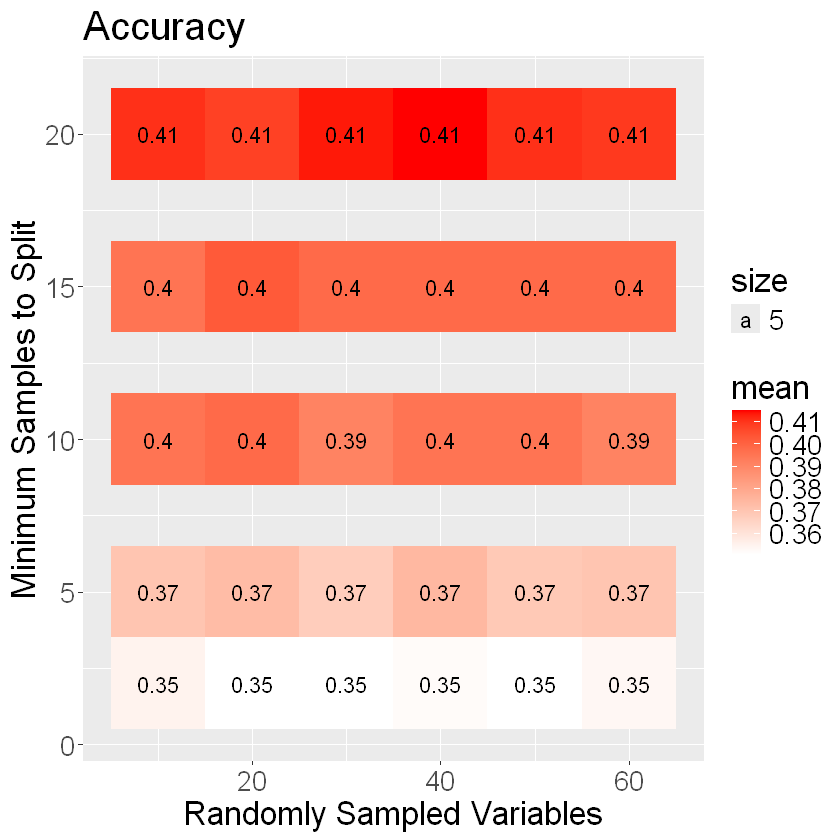

In [18]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

Ignoring unknown labels:
• colour : "Estimated Recall"


[1] "Best hyperparameters:"
20 
40 


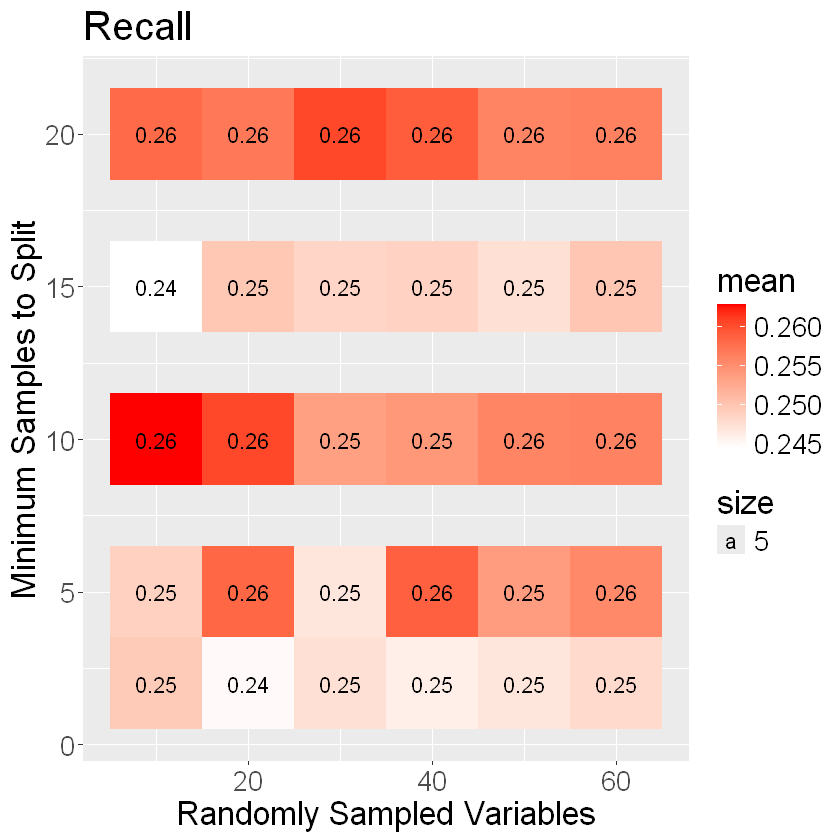

In [19]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "recall")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Recall", title="Recall") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters:")
print(best_params)

In [20]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    40    20 pre0_mod20_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 110."
Warning message:
"! 40 columns were requested but there were 4 predictors in the data.
ℹ 4 predictors will be used."


══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
0 Recipe Steps

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, mtry = min_cols(~40,      x), num.trees = ~1000, min.node.size = min_rows(~20, x),      importance = ~"impurity", num.threads = 1, verbose = FALSE,      seed = sample.int(10^5, 1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  1000 
Sample size:                      716 
Number of independent variables:  4 
Mtry:                             4 
Target node size:                 20 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.6108982 

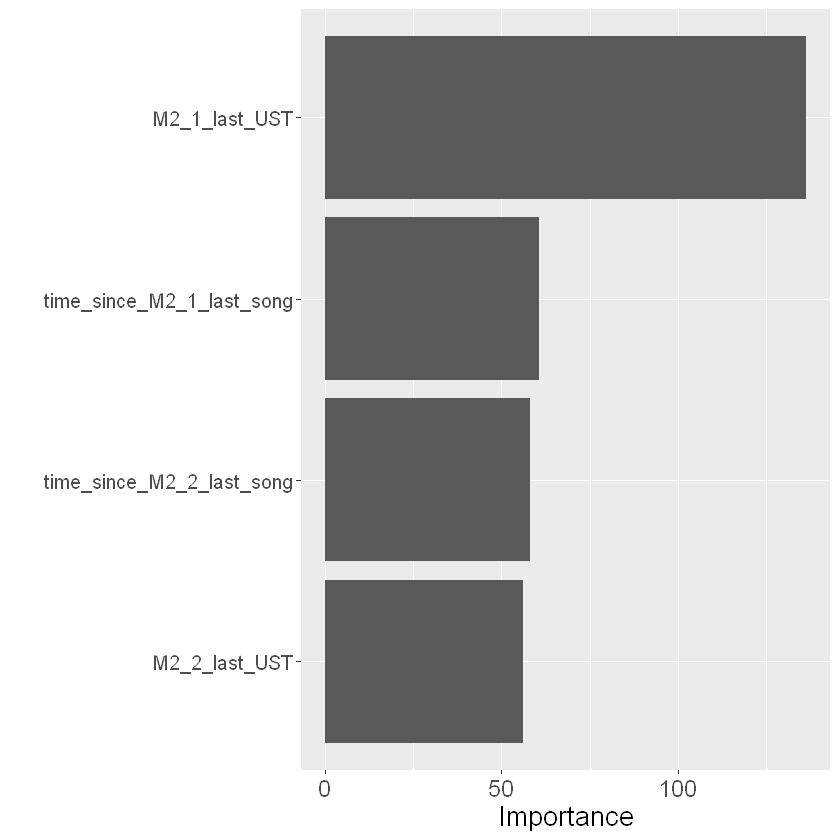

In [21]:
model %>% extract_fit_engine() %>% vip(num_features=10) +
  # theme_bw() + # Starting with a clean theme
  theme(
    axis.text.x = element_text(size = 14),       # X-axis tick labels
    axis.text.y = element_text(size = 12),       # Y-axis tick labels
    axis.title.x = element_text(size = 16),      # X-axis title
    axis.title.y = element_text(size = 16),      # Y-axis title
    plot.title = element_text(size = 18, face = "bold"), # Main plot title
    legend.text = element_text(size = 12),       # Legend labels
    legend.title = element_text(size = 14)       # Legend title
  )

In [22]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [23]:
# test_predictions

In [24]:
# What was the accuracy, precision, and recall of our model?
test_accuracy <- test_predictions %>% metrics(truth = UST, estimate = .pred_class) %>% filter(.metric == "accuracy")
test_accuracy

test_predictions %>% group_by(UST) %>% metrics(truth = UST, estimate = .pred_class) %>% filter(.metric == "accuracy") %>% arrange(desc(.estimate)) %>% 
    select(UST, .estimate) %>% rename(estimated_accuracy = .estimate) %>%
    left_join(n_ust %>% select(UST, n), by = "UST") 

test_predictions %>% group_by(UST) %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate)) # Precision = correct positive predictions / total positive predictions
test_predictions %>% group_by(UST) %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate)) # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.3680782


UST,estimated_accuracy,n
<fct>,<dbl>,<int>
28,0.6875000,67
104,0.6153846,48
9,0.5135135,98
8,0.5000000,20
20,0.4838710,58
6,0.4800000,42
105,0.4285714,52
13,0.3333333,51
4,0.3076923,35


Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 4, '1': 0, '4': 0, '6': 0, '8': 0, '10': 0, '12': 0, '13': 0, '15': 0,
'23': 0, '24': 0, '25': 0, '33': 0, '104': 0, '105': 0, '106': 0, '107': 0,
'108': 0, '109': 0, '110': 0, '111': 0, '112': 0, '113': 0, '114': 0"
Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 0, '4': 0, '6': 0, '8': 0, '10': 0, '12': 0, '15': 0, '23': 0, '24': 0,
'25': 0, '28': 0, '33': 0, '106

UST,.metric,.estimator,.estimate
<fct>,<chr>,<chr>,<dbl>
8,precision,macro,0.3333333
4,precision,macro,0.2500000
6,precision,macro,0.2000000
105,precision,macro,0.2000000
1,precision,macro,0.1666667
13,precision,macro,0.1666667
20,precision,macro,0.1428571
104,precision,macro,0.1428571
106,precision,macro,0.1428571


Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'1': 0, '4': 0, '6': 0, '8': 0, '9': 2, '10': 0, '12': 0, '13': 0, '15': 0,
'20': 1, '23': 0, '24': 0, '25': 0, '28': 1, '33': 0, '104': 0, '105': 0,
'106': 0, '107': 0, '108': 0, '109': 0, '110': 0, '111': 0, '112': 0, '113': 0,
'114': 0"
Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'0': 0, '4': 0, '6': 0, '8': 0, '9': 4, '10': 0, '12': 0, '13': 2, '15': 0,
'20': 2, '23': 0, '24': 0,

UST,.metric,.estimator,.estimate
<fct>,<chr>,<chr>,<dbl>
28,recall,macro,0.6875000
104,recall,macro,0.6153846
9,recall,macro,0.5135135
8,recall,macro,0.5000000
20,recall,macro,0.4838710
6,recall,macro,0.4800000
105,recall,macro,0.4285714
13,recall,macro,0.3333333
4,recall,macro,0.3076923


In [25]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  1  4  6  8  9 10 12 13 15 20 23 24 25 28 33 104 105 106 107 108
       0    0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0
       1    0  2  0  0  1  2  1  0  0  2  0  1  0  0  0  0   3   1   0   0   1
       4    0  0  4  6  0  1  0  1  1  0  0  2  3  0  1  0   1   0   3   1   0
       6    0  0  6 12  0  0  1  0  0  0  0  1  0  0  1  0   0   0   2   1   0
       8    0  0  0  3  2  0  1  0  0  0  1  0  2  0  0  0   0   0   1   0   0
       9    2  4  0  0  0 19  0  0  2  3 10  0  0  0  0  0   2   0   0   1   0
       10   0  0  0  0  0  1  3  0  0  0  2  0  0  0  2  0   0   5   0   1   2
       12   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0
       13   0  2  0  0  0  8  1  0  4  0  0  0  0  0  0  0   1   1   0   0   0
       15   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0   0
       20   1  2  1  0  1  4  3  0  1  0 15  0  1  0  0  0   2   0   0   0   0
       23   0  0  0  0  0  0  0  0  